# Assingment 4 Robynne Le Roux

### 1. Data processing

#### Imports

In [114]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import numpy as np
import matplotlib.pyplot as plt 
import os
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#### Load data

In [115]:
class FashionCSVDataset(Dataset):
    
    def __init__(self, csv_file, transform = None):
        
        data = np.loadtxt(csv_file, delimiter = ',', skiprows = 1) #Skip header row
        
        self.labels = data[:, 0].astype(np.int64) #First column is the label
        self.images = data[:, 1:].astype(np.float32) #Remaining columns are pixel values for a 28×28 image
        self.transform = transform 

    
    def __len__(self):
        
        return len( self.labels ) #Returns the nr samples needed by PyTorch’s DataLoader

    
    def __getitem__(self, idx): #fetches one sample
        
        label = self.labels[idx]
        image_pixels = self.images[idx]
        
        image = image_pixels.reshape(28, 28) #reshapes flat 784-pixel array into a 28×28 image

        # Apply transforms
        if self.transform:
            
            image = image.astype(np.uint8) # Convert to uint8 for transforms.ToTensor()
            image_tensor = self.transform(image) 
            label_tensor = torch.tensor(label, dtype = torch.long)
            
            return image_tensor, label_tensor
            
        return torch.tensor(image, dtype = torch.float32).unsqueeze(0), torch.tensor(label, dtype = torch.long) #if no transformation shape becomes [1, 28, 28] manually


BATCH_SIZE = 64 #found on calude that this is a common batch size for image classification (ie best)
#transforming the dataset by converting to tensors and normalizing
transform = transforms.Compose([ transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,)) ])

data_dir = "data"
train_dataset = FashionCSVDataset( csv_file = os.path.join(data_dir, 'fashion-mnist_train.csv'), transform = transform)
validation_dataset = FashionCSVDataset( csv_file = os.path.join(data_dir, 'fashion-mnist_test.csv'), transform = transform )

train_dataloader = DataLoader( train_dataset, batch_size = BATCH_SIZE, shuffle = True ) #shuffling for training
validation_dataloader = DataLoader( validation_dataset, batch_size = BATCH_SIZE, shuffle = False )

#### Testing data loading

In [116]:
print("Data Processing Verification:")
print(f"Train dataset size: {len(train_dataset)}") #should be 60000
print(f"Validation dataset size: {len(validation_dataset)}") #should be 10000
print(f"DataLoader Batch Size: {BATCH_SIZE}") #what i definied bacth size to (64)
print(f"Number of training batches -steps per epoch: {len(train_dataloader)}") #60000 / 64
print(f"Number of validation batches: {len(validation_dataloader)}\n") #10000 / 64

# shape single batch
X, y = next(iter(train_dataloader))
print(f"Shape of Image Batch: {X.shape}") # Should be BATCH_SIZE, 1, 28, 28
print(f"Shape of Label Batch: {y.shape}") # Should be BATCH_SIZE -1 label for each image in batch
print(f"Data type of X: {X.dtype}") #torch.float32 is the standard type for image inputs in PyTorch
print(f"Pixel min value: {X.min().item():.2f}, max value: {X.max().item():.2f}") # Should be +- (-1.0, 1.0) due to normalisation

Data Processing Verification:
Train dataset size: 60000
Validation dataset size: 10000
DataLoader Batch Size: 64
Number of training batches -steps per epoch: 938
Number of validation batches: 157

Shape of Image Batch: torch.Size([64, 1, 28, 28])
Shape of Label Batch: torch.Size([64])
Data type of X: torch.float32
Pixel min value: -1.00, max value: 1.00


### 2. Building and training a Baseline model 

#### Define the Network Architecture 

In [117]:
class BaselineMLP(nn.Module):
    
    def __init__(self):
        
        super().__init__()
        
        # Input layer: 1x28x28 -> 784
        self.flatten = nn.Flatten() 
        
        self.mlp_stack = nn.Sequential(
            
            # Hidden Layer 1: inputs -> 128 outputs, ReLU
            nn.Linear(28*28, 128),
            nn.ReLU(),
            
            # Hidden Layer 2: 128 inputs -> 64 outputs, ReLU
            nn.Linear(128, 64),
            nn.ReLU(),
            
            # Output Layer: 64 inputs -> 10 outputs (for 10 classes)
            nn.Linear(64, 10)
        )
        
    def forward(self, x): #pytorch requires basline class forward not forwardPropagation
        
        x = self.flatten(x) # Pass input through the flatten layer
        output = self.mlp_stack(x) # Pass the flattened vector through the MLP stack
        
        return output

#### Training Loop

In [118]:
def train_model(model, train_loader, val_loader, loss_fn, optimizer, epochs = 10, device = 'cpu'):
    
    model.to(device)

    train_losses = [] #used in part 4 for plotting loss curves
    val_losses = [] #used in part 4 for plotting loss curves
    final_train_acc = 0.0 # Variable to store the final epoch's training accuracy


    for epoch in range(epochs):
        # Taining
        model.train()
        running_loss = 0.0
        correct = 0 
        total = 0

        for images, labels in train_loader:
            
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = loss_fn(outputs, labels)

            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Track loss and accuracy
            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        train_acc = correct / total
        train_losses.append(running_loss / len(train_loader))
        final_train_acc = train_acc 
        
        # Validation (inside epoch loop)
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
    
        with torch.no_grad(): #no gradient calculations -No .backward() or .step() can be called inside this block
        
            for images, labels in val_loader:
            
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = loss_fn(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        val_losses.append(val_loss / len(val_loader))
        val_acc = correct / total    
        print(f"Epoch {epoch + 1} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | Val Acc: {train_acc:.4f}")
    
    return val_acc, final_train_acc, train_losses, val_losses

#### Train the Baseline Model

In [120]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") #checks for GPU (CUDA) as GPU is much faster for training

model = BaselineMLP()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

baseline_val_acc,baseline_train_acc, baseline_train_loss, baseline_val_losses = train_model(model, train_dataloader, validation_dataloader, loss_fn, optimizer, epochs = 10, device = device)

Epoch 1 | Train Loss: 0.5241 | Val Loss: 0.4101 | Val Acc: 0.8102
Epoch 2 | Train Loss: 0.3854 | Val Loss: 0.3622 | Val Acc: 0.8591
Epoch 3 | Train Loss: 0.3450 | Val Loss: 0.3634 | Val Acc: 0.8719
Epoch 4 | Train Loss: 0.3211 | Val Loss: 0.3285 | Val Acc: 0.8809
Epoch 5 | Train Loss: 0.3010 | Val Loss: 0.3240 | Val Acc: 0.8876
Epoch 6 | Train Loss: 0.2881 | Val Loss: 0.3126 | Val Acc: 0.8923
Epoch 7 | Train Loss: 0.2726 | Val Loss: 0.3212 | Val Acc: 0.8981
Epoch 8 | Train Loss: 0.2596 | Val Loss: 0.3272 | Val Acc: 0.9032
Epoch 9 | Train Loss: 0.2493 | Val Loss: 0.3083 | Val Acc: 0.9062
Epoch 10 | Train Loss: 0.2393 | Val Loss: 0.3115 | Val Acc: 0.9103


### 3. Hyperparameter Optimisation Experiment

#### Investigating 3 hyperparameters (learning rates,optimisers,dropout rates) using script (nested loops)

In [ ]:
class TunableMLP(nn.Module):
    '''modifying BaselineMLPto be flexible with diff hyperparameters'''
    
    def __init__(self, dropout_rate=0.25):
        
        super().__init__()
        self.flatten = nn.Flatten()
        
        self.mlp_stack = nn.Sequential(
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        
        x = self.flatten(x)
        return self.mlp_stack(x)

#adapted grid search from previous assingments
results = [] #final validation accuracy for each run stored in this data structure

learning_rates = [0.01, 0.001, 0.0001] #hyperparameter 1
optimisers = ['Adam', 'SGD', 'RMSprop'] #hyperparameter 2
dropout_rates = [0.1, 0.25, 0.5] #hyperparameter 3

#script: nested loops
for lr in learning_rates: 
    
    for opt_name in optimisers:
        
        for drop in dropout_rates:
            
            model = TunableMLP(dropout_rate = drop)
            loss_fn = nn.CrossEntropyLoss()

            if opt_name == 'Adam':
                
                optimizer = torch.optim.Adam(model.parameters(), lr = lr)
                
            elif opt_name == 'SGD':
                
                optimizer = torch.optim.SGD(model.parameters(), lr = lr)
                
            elif opt_name == 'RMSprop':
                
                optimizer = torch.optim.RMSprop(model.parameters(), lr = lr)

            print(f"\nTraining with lr = {lr}, optimiser = {opt_name}, dropout = {drop}")
            val_acc, final_train_acc, train_losses, val_losses = train_model(model, train_dataloader, validation_dataloader, loss_fn, optimizer, epochs = 10, device = device)

            results.append({
                'learning_rate': lr,
                'optimiser': opt_name,
                'dropout': drop,
                'final_train_accuracy': final_train_acc,
                'val_accuracy': val_acc,
                'train_loss': train_losses,
                'val_loss': val_losses
            })
            
#runs 27 experiments (3*3*3) and prints the final validation accuracy for each combination           
print("\nHyperparameter Tuning Results:")
for r in results:
    
    print(f"LR={r['learning_rate']}, Optimiser={r['optimiser']}, Dropout={r['dropout']} = Val Acc={r['val_accuracy']:.4f} | Train Acc={r['final_train_accuracy']:.4f}") # Updated print for clarity


Training with lr = 0.01, optimiser = Adam, dropout = 0.1
Epoch 1 | Train Loss: 0.6326 | Val Loss: 0.4822 | Val Acc: 0.7751
Epoch 2 | Train Loss: 0.5434 | Val Loss: 0.4732 | Val Acc: 0.8079
Epoch 3 | Train Loss: 0.5256 | Val Loss: 0.4510 | Val Acc: 0.8185
Epoch 4 | Train Loss: 0.5155 | Val Loss: 0.5155 | Val Acc: 0.8204
Epoch 5 | Train Loss: 0.5219 | Val Loss: 0.4794 | Val Acc: 0.8196
Epoch 6 | Train Loss: 0.5185 | Val Loss: 0.4635 | Val Acc: 0.8218
Epoch 7 | Train Loss: 0.5093 | Val Loss: 0.4529 | Val Acc: 0.8264
Epoch 8 | Train Loss: 0.4989 | Val Loss: 0.4326 | Val Acc: 0.8285


### Part 4: Analysis and Report 

#### Experimental results in a well-formatted table 

In [132]:
df = pd.DataFrame(results)
# Apply explicit rounding to both accuracy columns for consistensy
df['val_accuracy'] = df['val_accuracy'].round(4)
df['final_train_accuracy'] = df['final_train_accuracy'].round(4)

# Table 1: Validation Accuracy (Sorted by best performance
df_val_sorted = df.sort_values(by = 'val_accuracy', ascending = False).drop(columns=['train_loss', 'val_loss', 'final_train_accuracy'])
print('Table 1: Validation Accuracy (Best to Worst):\n\n', df_val_sorted)

# Table 2: Training Accuracy (Sorted by best performance) 
df_train_sorted = df.sort_values(by = 'final_train_accuracy', ascending = False).drop(columns=['train_loss', 'val_loss', 'val_accuracy'])

# Renaming the column for clarity in the final output table
df_train_sorted.rename(columns = {'final_train_accuracy': 'train_accuracy'}, inplace = True)
print('\n\nTable 2: Training Accuracy (Best to Worst):\n\n', df_train_sorted)


Table 1: Validation Accuracy (Best to Worst):

     learning_rate optimiser  dropout  val_accuracy
15         0.0010   RMSprop     0.10        0.8863
10         0.0010      Adam     0.25        0.8842
9          0.0010      Adam     0.10        0.8841
16         0.0010   RMSprop     0.25        0.8793
24         0.0001   RMSprop     0.10        0.8780
18         0.0001      Adam     0.10        0.8741
19         0.0001      Adam     0.25        0.8721
25         0.0001   RMSprop     0.25        0.8685
4          0.0100       SGD     0.25        0.8622
26         0.0001   RMSprop     0.50        0.8621
11         0.0010      Adam     0.50        0.8617
17         0.0010   RMSprop     0.50        0.8593
3          0.0100       SGD     0.10        0.8585
20         0.0001      Adam     0.50        0.8569
0          0.0100      Adam     0.10        0.8518
5          0.0100       SGD     0.50        0.8472
6          0.0100   RMSprop     0.10        0.8403
1          0.0100      Adam     0.

####  Visualisations (for interpretation)

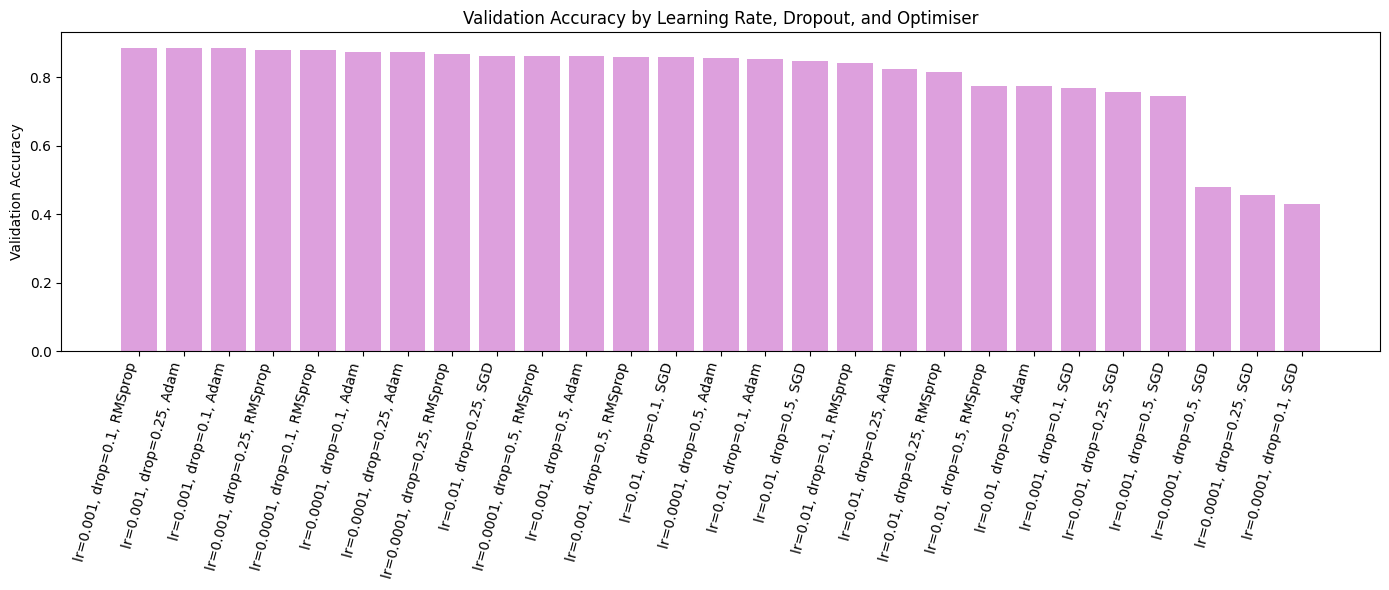

In [133]:
'''Bar graph plain (for interpretation) - Hyperparameter Impact'''
# Convert results to DataFrame
df = pd.DataFrame(results)

# Create a new column that combines all 3 hyperparameters for the x-axis label
df['config'] = df.apply(lambda row: f"lr={row['learning_rate']}, drop={row['dropout']}, {row['optimiser']}", axis=1)

# Sort by accuracy for visual clarity
df_sorted = df.sort_values(by='val_accuracy', ascending=False)

# Plot
plt.figure(figsize=(14, 6))
bars = plt.bar(df_sorted['config'], df_sorted['val_accuracy'], color ='plum')

# Rotate x-axis labels for readability
plt.xticks(rotation=75, ha='right')
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Learning Rate, Dropout, and Optimiser")
plt.tight_layout()
plt.show()

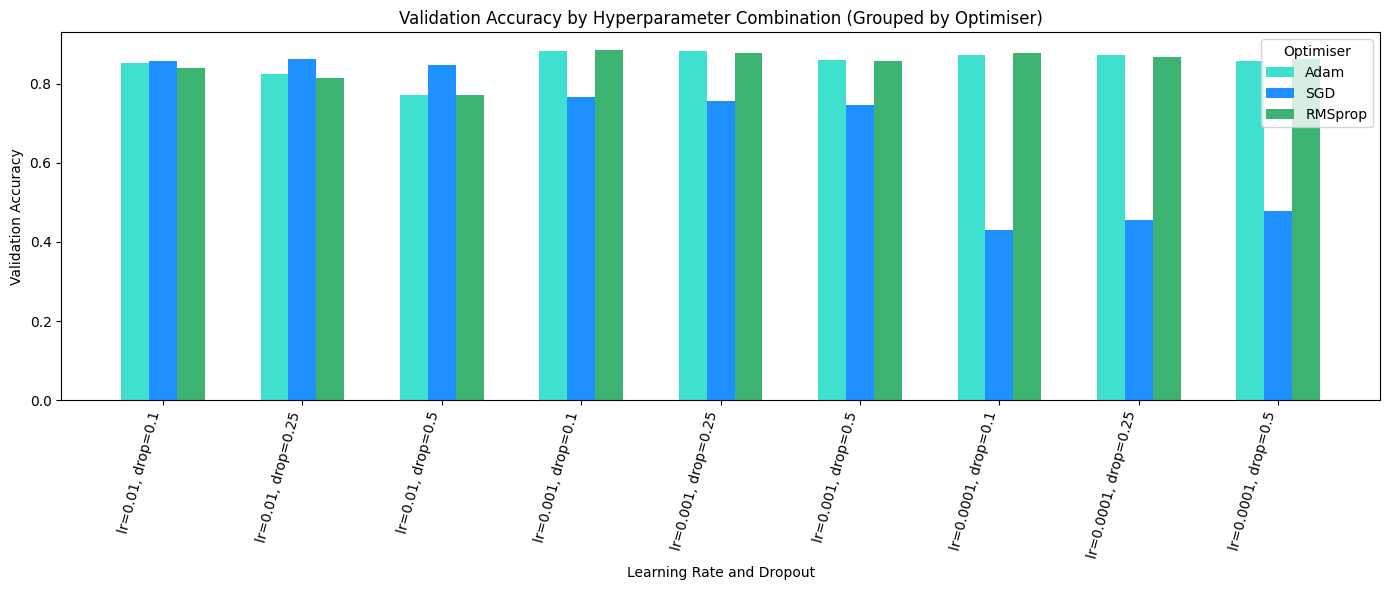

In [134]:
'''Bar graph grouped (for interpretation) - Hyperparameter Impact'''
# Convert results to DataFrame
df = pd.DataFrame(results)

# Create a combined label for x-axis: "lr=0.001, drop=0.25"
df['config'] = df.apply(lambda row: f"lr={row['learning_rate']}, drop={row['dropout']}", axis=1)

# Get unique configs and optimisers
configs = df['config'].unique()
optimisers = df['optimiser'].unique()
bar_width = 0.2
x = range(len(configs))

# Define custom colours for each optimiser
colour_map = {
    'Adam': 'turquoise',
    'SGD': 'dodgerblue',
    'RMSprop': 'mediumseagreen'
}

plt.figure(figsize=(14, 6))

for i, opt in enumerate(optimisers):
    subset = df[df['optimiser'] == opt]
    # Align bars for each optimiser
    offsets = [pos + i * bar_width for pos in x]
    # Match val_accuracy to config order
    heights = [subset[subset['config'] == cfg]['val_accuracy'].values[0] if cfg in subset['config'].values else 0 for cfg in configs]
    plt.bar(offsets, heights, width = bar_width, label = opt, color = colour_map[opt])

# Label axes
plt.xticks([pos + bar_width for pos in x], configs, rotation = 75, ha ='right')
plt.xlabel("Learning Rate and Dropout")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Hyperparameter Combination (Grouped by Optimiser)")
plt.legend(title = "Optimiser")
plt.tight_layout()
plt.show()

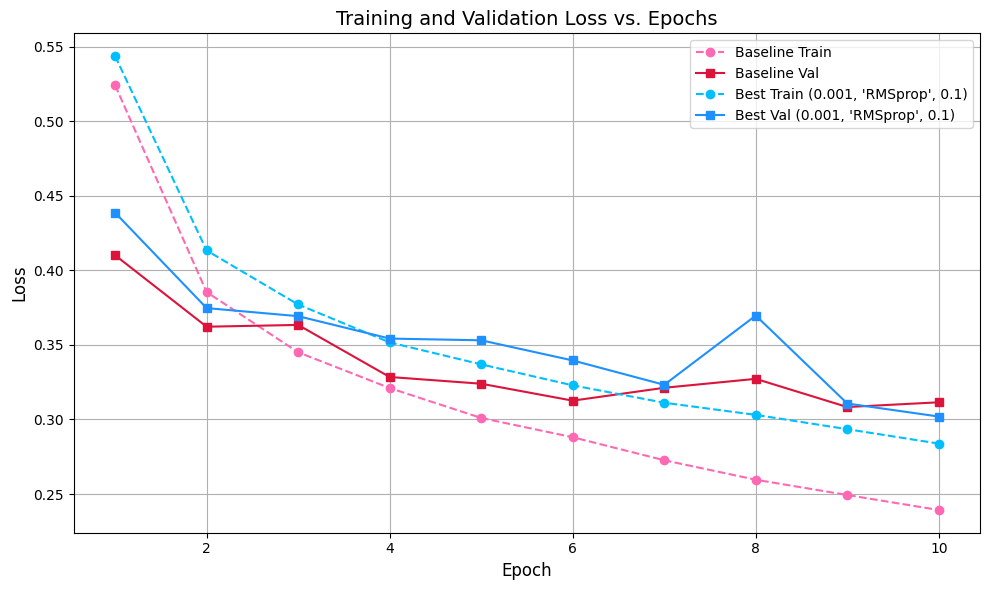

In [135]:
'''Loss Curves - Hyperparameter Impact'''

# Use stored baseline loss directly
baseline_train = baseline_train_loss
baseline_val = baseline_val_losses

best_train = None
best_val = None
best_acc = 0.0

# Find best model from results
for r in results:
    
    if r['val_accuracy'] > best_acc:
        best_acc = r['val_accuracy']
        best_train = r['train_loss']
        best_val = r['val_loss']
        best_config = (r['learning_rate'], r['optimiser'], r['dropout'])

# Plot
epochs = list(range(1, len(baseline_loss) + 1))
plt.figure(figsize=(10, 6))

# Baseline
plt.plot(epochs, baseline_train, label = "Baseline Train", linestyle = "--", marker = "o", color = "hotpink") # Custom colours
plt.plot(epochs, baseline_val, label = "Baseline Val", linestyle = "-", marker = "s", color = "crimson") # Custom colours

# Best
plt.plot(epochs, best_train, label = f"Best Train {best_config}", linestyle = "--", marker = "o", color = "deepskyblue") # Custom colours
plt.plot(epochs, best_val, label = f"Best Val {best_config}", linestyle = "-", marker = "s", color = "dodgerblue") # Custom colours

plt.title("Training and Validation Loss vs. Epochs", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Best model configuration found: LR=0.001, Optimiser=RMSprop, Dropout=0.1

Retraining the best model for 10 epochs
Epoch 1 | Train Loss: 0.5474 | Val Loss: 0.4352 | Val Acc: 0.7990
Epoch 2 | Train Loss: 0.4160 | Val Loss: 0.4096 | Val Acc: 0.8500
Epoch 3 | Train Loss: 0.3795 | Val Loss: 0.3671 | Val Acc: 0.8626
Epoch 4 | Train Loss: 0.3543 | Val Loss: 0.3448 | Val Acc: 0.8713
Epoch 5 | Train Loss: 0.3368 | Val Loss: 0.3329 | Val Acc: 0.8770
Epoch 6 | Train Loss: 0.3252 | Val Loss: 0.3144 | Val Acc: 0.8816
Epoch 7 | Train Loss: 0.3121 | Val Loss: 0.3142 | Val Acc: 0.8843
Epoch 8 | Train Loss: 0.3039 | Val Loss: 0.3177 | Val Acc: 0.8885
Epoch 9 | Train Loss: 0.2948 | Val Loss: 0.3339 | Val Acc: 0.8911
Epoch 10 | Train Loss: 0.2854 | Val Loss: 0.3281 | Val Acc: 0.8945


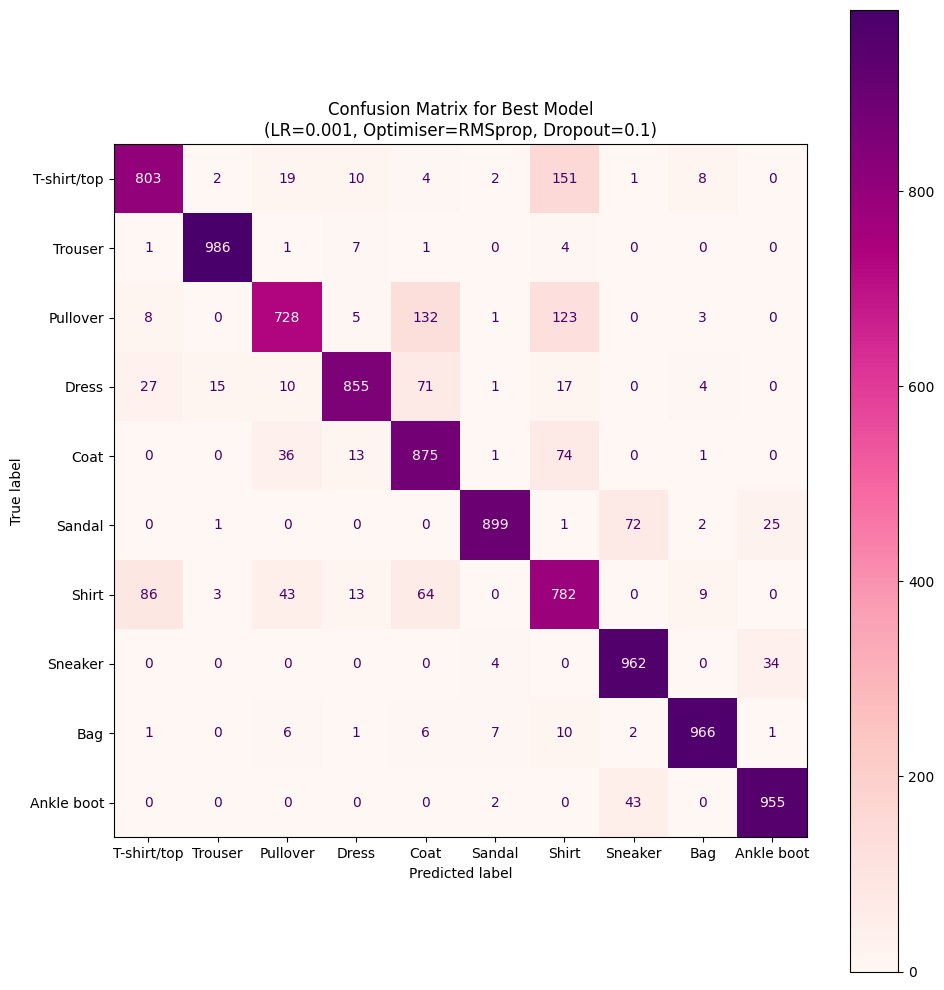

In [130]:
'''Confusion Matrix - Hyperparameter Impact'''

# Step 1: Extract best hyperparameters from results
best_result = max(results, key=lambda r: r['val_accuracy'])
best_lr = best_result['learning_rate']
best_opt_name = best_result['optimiser']
best_drop = best_result['dropout']

print(f"Best model configuration found: LR={best_lr}, Optimiser={best_opt_name}, Dropout={best_drop}")

# Step 2: Recreate and retrain the best model
best_model = TunableMLP(dropout_rate=best_drop)
loss_fn = nn.CrossEntropyLoss()

if best_opt_name == 'Adam':
    optimizer = torch.optim.Adam(best_model.parameters(), lr=best_lr)
elif best_opt_name == 'SGD':
    optimizer = torch.optim.SGD(best_model.parameters(), lr=best_lr)
elif best_opt_name == 'RMSprop':
    optimizer = torch.optim.RMSprop(best_model.parameters(), lr=best_lr)

print("\nRetraining the best model for 10 epochs")
train_model(best_model, train_dataloader, validation_dataloader, loss_fn, optimizer, epochs=10, device=device)




# Step 3: Define confusion matrix plotting function
def plot_confusion_matrix(model, dataloader, device='cpu', class_names=None, cmap_color='Blues'):
    model.eval()
    model.to(device)

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(10, 10))
    disp.plot(ax=ax, cmap=cmap_color, colorbar=True)
    plt.title(f"Confusion Matrix for Best Model\n(LR={best_lr}, Optimiser={best_opt_name}, Dropout={best_drop})")
    plt.tight_layout()
    plt.show()

# Step 4: Define class names and plot
fashion_mnist_class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
plot_confusion_matrix(
    best_model,
    validation_dataloader,
    device=device,
    class_names=fashion_mnist_class_names,
    cmap_color='RdPu'  # Optional: change to 'Blues', 'Greens', etc.
)